# 06 · Model evaluation

The selected pipeline (logistic regression, no rebalancing), evaluated with the full protocol:

* **Threshold:** chosen on out-of-fold training predictions.
* **Held-out estimate:** one evaluation on the untouched 294-employee test set.
* **Uncertainty:** stratified bootstrap confidence intervals around every held-out metric.
* **Further checks:** calibration, threshold trade-offs, a learning curve and error rates by group.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from talentscope import config
from talentscope.reporting import figures as F
F.setup()
print("TalentScope root:", ROOT.name, "| seed", config.RANDOM_SEED)

TalentScope root: TalentScope | seed 42


In [2]:
from talentscope.modeling import load_bundle
from talentscope.evaluation import compute_metrics, threshold_sweep, select_threshold, bootstrap_ci, curve_points, calibration_table
from talentscope.data import load_dataset, split_features_target
from talentscope.preprocessing import make_split
b = load_bundle()
df = load_dataset(); X, y = split_features_target(df)
X_train, X_test, y_train, y_test = make_split(X, y)
model = b.load_model()
p_test = model.predict_proba(X_test)[:, 1]
assert np.allclose(p_test, b.test_predictions.set_index("row_id").loc[X_test.index, "probability"], atol=1e-6)
oof = b.oof[b.selection["combo"]].to_numpy(); y_oof = b.oof["actual_left"].to_numpy()
print(b.label, "| threshold", b.threshold)

Logistic regression + No rebalancing | threshold 0.36


## 1. Choosing the threshold on training data

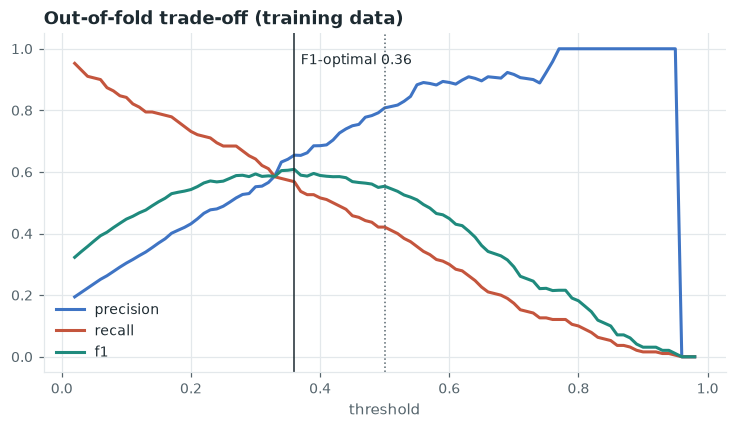

selected threshold 0.36 (OOF F1 0.608); saved threshold 0.36


In [3]:
sweep = threshold_sweep(y_oof, oof)
thr, best = select_threshold(y_oof, oof, "f1")
fig, ax = plt.subplots(figsize=(8, 4))
for col, c in (("precision", F.BLUE), ("recall", F.CLAY), ("f1", F.TEAL)):
    ax.plot(sweep["threshold"], sweep[col], color=c, lw=2, label=col)
ax.axvline(thr, color=F.INK, lw=1); ax.text(thr + 0.01, 0.95, f"F1-optimal {thr:.2f}", fontsize=9)
ax.axvline(0.5, color=F.MUTED, lw=1, ls=":"); ax.set_xlabel("threshold"); ax.legend(); ax.set_title("Out-of-fold trade-off (training data)")
plt.show()
print(f"selected threshold {thr:.2f} (OOF F1 {best:.3f}); saved threshold {b.threshold:.2f}")

The default 0.5 threshold is too high for a 16% positive class. The F1-optimal point is lower, trading some precision
for much better recall. Because it was chosen on out-of-fold predictions, the test set below is a fair check of it.

## 2. Held-out results, once

In [4]:
m = compute_metrics(y_test, p_test, b.threshold)
ci = bootstrap_ci(y_test, p_test, b.threshold, n_resamples=1000, seed=42)
ci.assign(estimate=ci["estimate"].round(3), ci_low=ci["ci_low"].round(3), ci_high=ci["ci_high"].round(3))[["label", "estimate", "ci_low", "ci_high"]]

,label,estimate,ci_low,ci_high
0,PR-AUC,0.598,0.477,0.713
1,ROC-AUC,0.814,0.730,0.882
2,F1,0.530,0.405,0.645
3,Precision,0.611,0.472,0.758
4,Recall,0.468,0.340,0.617
5,Balanced accuracy,0.706,0.635,0.776
6,Accuracy,0.867,0.833,0.901
7,Specificity,0.943,0.915,0.968
8,Brier score,0.097,0.082,0.114


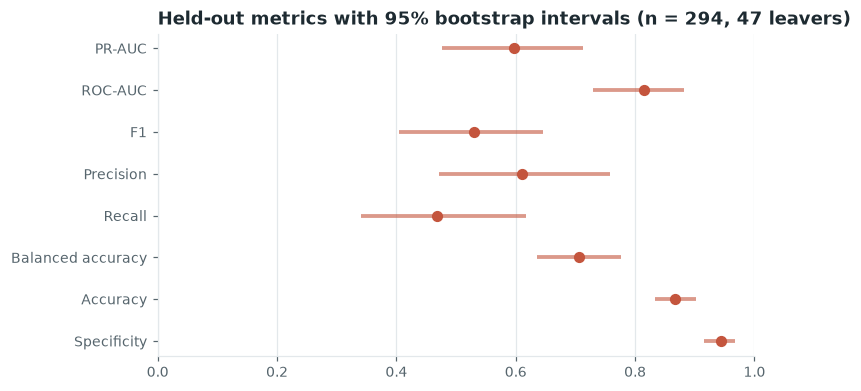

PR-AUC 0.598 against a chance level of 0.160; ROC-AUC 0.814


In [5]:
fig, ax = plt.subplots(figsize=(7, 3.8))
c2 = ci[ci.metric != "brier"].iloc[::-1]
ax.hlines(range(len(c2)), c2["ci_low"], c2["ci_high"], color=F.CLAY, lw=2.5, alpha=0.6)
ax.scatter(c2["estimate"], range(len(c2)), color=F.CLAY, zorder=3, s=40)
ax.set_yticks(range(len(c2)), c2["label"]); ax.set_xlim(0, 1); ax.grid(axis="y", visible=False)
ax.set_title(f"Held-out metrics with 95% bootstrap intervals (n = {len(y_test)}, {int(y_test.sum())} leavers)"); plt.show()
print(f"PR-AUC {m['pr_auc']:.3f} against a chance level of {y_test.mean():.3f}; ROC-AUC {m['roc_auc']:.3f}")

**Reading the uncertainty.** With only 47 leavers in the test set, the PR-AUC interval spans roughly ±0.12. The
held-out PR-AUC sits inside the range the cross-validation predicted (mean about 0.66, fold SD about 0.06), slightly
lower but consistent. Small held-out samples routinely produce gaps of this size, which is why model choices were made
on CV results, not on this number.

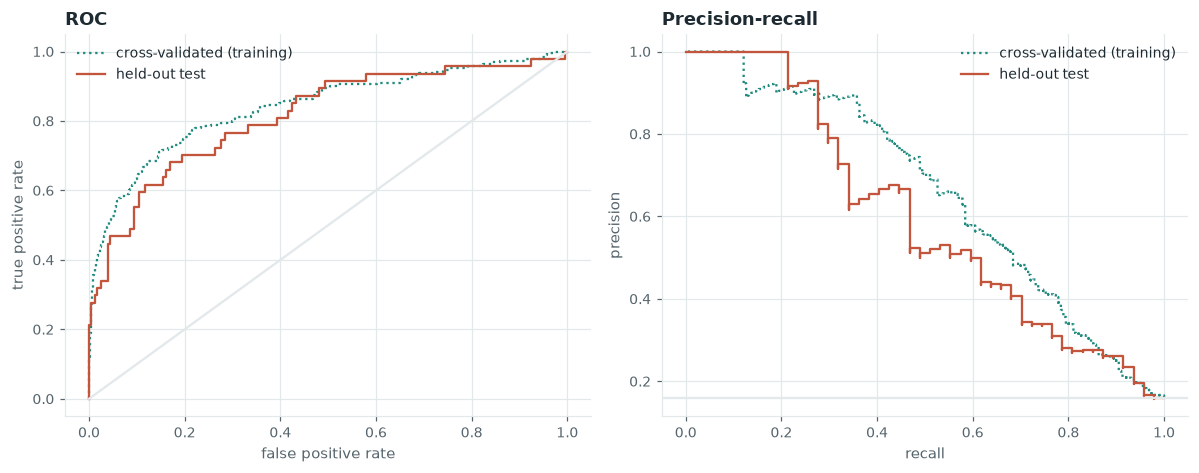

In [6]:
from talentscope.reporting.figures import TEAL, CLAY
cp, co = curve_points(y_test, p_test), curve_points(y_oof, oof)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
axes[0].plot(co["fpr"], co["tpr"], color=TEAL, ls=":", label="cross-validated (training)")
axes[0].plot(cp["fpr"], cp["tpr"], color=CLAY, label="held-out test"); axes[0].plot([0, 1], [0, 1], color=F.GRID)
axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("true positive rate"); axes[0].legend(); axes[0].set_title("ROC")
axes[1].step(co["recall"], co["precision"], color=TEAL, ls=":", where="post", label="cross-validated (training)")
axes[1].step(cp["recall"], cp["precision"], color=CLAY, where="post", label="held-out test")
axes[1].axhline(y_test.mean(), color=F.GRID); axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision"); axes[1].legend()
axes[1].set_title("Precision-recall"); plt.tight_layout(); plt.show()

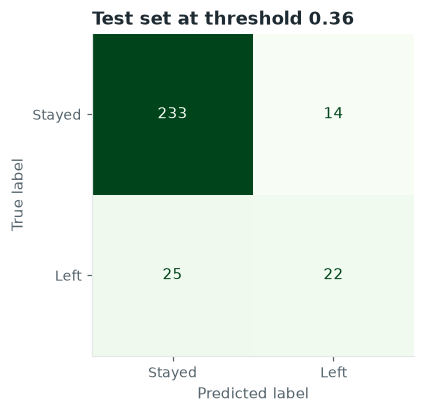

Caught 22 of 47 leavers; 14 of 247 stayers flagged by mistake.


,class,precision,recall,f1-score,support
0,Stayed,0.903,0.943,0.923,247.000
1,Left,0.611,0.468,0.530,47.000
2,accuracy,0.867,0.867,0.867,0.867
3,macro avg,0.757,0.706,0.726,294.000
4,weighted avg,0.856,0.867,0.860,294.000


In [7]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
cm = confusion_matrix(y_test, (p_test >= b.threshold).astype(int))
fig, ax = plt.subplots(figsize=(4.2, 3.8))
ConfusionMatrixDisplay(cm, display_labels=["Stayed", "Left"]).plot(ax=ax, cmap="Greens", colorbar=False); ax.grid(False)
ax.set_title(f"Test set at threshold {b.threshold:.2f}"); plt.show()
print(f"Caught {cm[1,1]} of {cm[1].sum()} leavers; {cm[0,1]} of {cm[0].sum()} stayers flagged by mistake.")
b.classification_report

## 3. Calibration

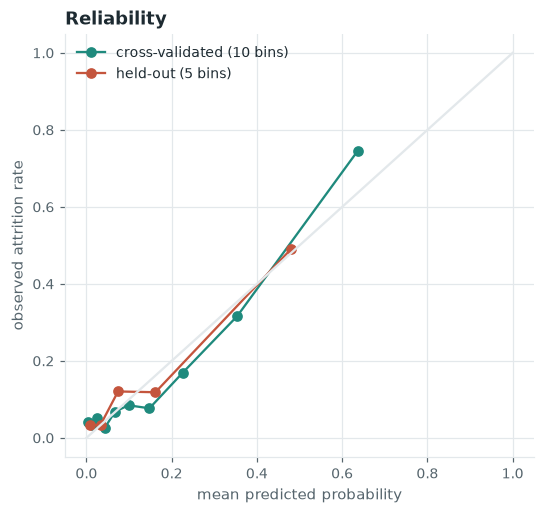

Brier score 0.0971 vs 0.1343 for always predicting the base rate


In [8]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for t, (yy, pp, bins) in {"cross-validated (10 bins)": (y_oof, oof, 10), "held-out (5 bins)": (y_test.to_numpy(), p_test, 5)}.items():
    c = calibration_table(yy, pp, bins)
    ax.plot(c["mean_predicted"], c["observed_rate"], "o-", label=t)
ax.plot([0, 1], [0, 1], color=F.GRID); ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed attrition rate")
ax.legend(); ax.set_title("Reliability"); plt.show()
print(f"Brier score {m['brier']:.4f} vs {y_test.mean() * (1 - y_test.mean()):.4f} for always predicting the base rate")

Without rebalancing, the logistic regression's probabilities are roughly calibrated: a 30% score means about 30% of
such employees left. That is what lets the risk simulator report a probability and an empirical reliability range
instead of a bare label. A rebalanced model would overstate every probability.

## 4. Is more data likely to help? Learning curve (training split only)

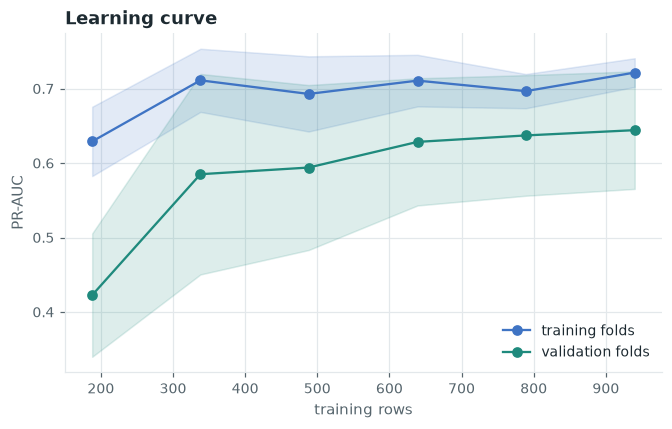

,rows,train PR-AUC,validation PR-AUC
0,188,0.629,0.423
1,338,0.711,0.585
2,488,0.693,0.594
3,639,0.711,0.629
4,789,0.697,0.637
5,940,0.722,0.644


In [9]:
from sklearn.model_selection import learning_curve, StratifiedKFold
from talentscope.modeling import build_pipeline
pipe = build_pipeline("logreg", "none", 42, y_train).set_params(model__C=b.best_params["logreg|none"]["C"])
sizes, tr_s, va_s = learning_curve(pipe, X_train, y_train, train_sizes=np.linspace(0.2, 1.0, 6),
                                   cv=StratifiedKFold(5, shuffle=True, random_state=3), scoring="average_precision", n_jobs=-1)
fig, ax = plt.subplots(figsize=(7, 4))
for s, c, lab in ((tr_s, F.BLUE, "training folds"), (va_s, F.TEAL, "validation folds")):
    ax.plot(sizes, s.mean(1), "o-", color=c, label=lab); ax.fill_between(sizes, s.mean(1) - s.std(1), s.mean(1) + s.std(1), color=c, alpha=0.15)
ax.set_xlabel("training rows"); ax.set_ylabel("PR-AUC"); ax.legend(); ax.set_title("Learning curve"); plt.show()
pd.DataFrame({"rows": sizes, "train PR-AUC": tr_s.mean(1), "validation PR-AUC": va_s.mean(1)})

Validation PR-AUC is still rising at the full training size, and the gap to training PR-AUC is narrowing slowly. More
employees would probably help, which reinforces the small-sample limitation. Using the full training split, with no
sub-sampling cap, was the right call.

## 5. Error rates by group (responsible-AI check)

In [10]:
gm = pd.read_csv(b.explain_dir / "group_metrics.csv")
gm[["attribute", "group", "n", "actual_leavers", "observed_rate", "flagged_rate", "recall_tpr", "false_positive_rate", "precision"]]

,attribute,group,n,actual_leavers,observed_rate,flagged_rate,recall_tpr,false_positive_rate,precision
0,Gender,Male,178,31,0.174,0.118,0.419,0.054,0.619
1,Gender,Female,116,16,0.138,0.129,0.562,0.060,0.600
2,AgeBand,26-35,121,20,0.165,0.124,0.550,0.040,0.733
3,AgeBand,36-45,98,11,0.112,0.082,0.455,0.034,0.625
4,AgeBand,46-55,37,6,0.162,0.054,0.167,0.032,0.500
5,AgeBand,18-25,27,7,0.259,0.407,0.714,0.300,0.455
6,AgeBand,56+,11,3,0.273,0.000,0.000,0.000,NaN
7,MaritalStatus,Married,133,18,0.135,0.060,0.278,0.026,0.625
8,MaritalStatus,Single,97,25,0.258,0.268,0.600,0.153,0.577
9,MaritalStatus,Divorced,64,4,0.062,0.031,0.500,0.000,1.000


Group sizes in the test set are small, with some under 40 and few leavers, so differences of 10 to 20 points can arise
by chance. Two patterns are still worth flagging for anyone extending this work:

* **Young employees (18 to 25)** are flagged far more often, with a much higher false-positive rate. The model has
  learned "young ⇒ risk" from career-stage attributes.
* **Employees aged 46 and over** have low recall: the few who leave are mostly missed.

Any real deployment would need a fairness review on real outcomes. Removing protected attributes (age, gender, marital
status) does not by itself fix this, because tenure, level and income carry similar information.

## Summary

| | Value |
|---|---|
| Threshold | chosen on out-of-fold predictions |
| Held-out PR-AUC | see the table above, with its 95% interval |
| Calibration | close to the diagonal; Brier below the base-rate model |
| Main limitation | 47 test leavers, so wide intervals; the learning curve suggests more data would help |